# Avaliação Modelo 2 ( corretor )

In [1]:
import re
import os
import string
import unicodedata
import pandas as pd
import spacy as scy
from joblib import load
from itertools import product
from unidecode import unidecode
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
import os
from dotenv import load_dotenv
from pathlib import Path

# Como o notebook está em 'corretor/src/3_avaliacao' e o .env em 'corretor',
# precisamos voltar duas pastas (../..) para achar o arquivo.
env_path = Path('../../.env')

# Carrega o arquivo explicitamente
load_dotenv(dotenv_path=env_path)

True

In [3]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\joaol\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Passo 1) Carregar o modelo1

O modelo1 inicial será utilizado para realização da predição dos tokens dos relatos. A saída desse modelo será utilizada para obtenção dos dados de entrada para o modelo2.

In [4]:
rf_e2 = load("../../rf_exp2.joblib")

In [5]:
PATH_BASE_TESTES_FINAIS = os.getenv('PATH_BASE_TESTES_FINAIS')
PATH_GABARITO_CORRETOR = os.getenv('PATH_GABARITO_CORRETOR')
PATH_FALSOS_POSITIVOS_MODELO_1 = os.getenv('PATH_FALSOS_POSITIVOS_MODELO_1')
PATH_FALSOS_POSITIVOS_MODELO_2 = os.getenv('PATH_FALSOS_POSITIVOS_MODELO_2')

## Passo 2) Carregar o modelo Corretor

In [6]:
rf_corretor = load('../../rf_corretor.joblib')

## Passo 3) Carregar os dados para predição

In [7]:
base_relato = pd.read_csv(PATH_BASE_TESTES_FINAIS)

In [8]:
base_relato.shape

(1886, 3)

### EDA

In [9]:
gab = pd.read_csv(PATH_GABARITO_CORRETOR)
gab.shape

(11625, 2)

In [10]:
teste_base_relato = base_relato.copy()

In [11]:
lista_nomes = []
lista_palavras = []

In [12]:
lista_nomes = []
lista_palavras = []

for n_bop, text in zip(teste_base_relato['n_bop'], teste_base_relato['relato']): 
    palavras = text.split()
    df = pd.DataFrame(palavras, columns=['palavra'])

    for _, row in df.iterrows():
        y_true_row = gab[gab['palavra'] == row['palavra']]

        if not y_true_row.empty:
            y_true_value = y_true_row['y'].iloc[0]

            if y_true_value == 0: 
                lista_palavras.append({'palavra': row['palavra'], 'y_palavra': y_true_value})

            elif y_true_value == 1:
                lista_nomes.append({'nome': row['palavra'], 'y_nome': y_true_value})

In [13]:
nomes = pd.DataFrame(lista_nomes)
nomes

,nome,y_nome
0,ALICE,1
1,MORAES,1
2,DR.,1
3,PAULO,1
4,SOUSA,1
...,...,...
20535,DR.,1
20536,THIAGO,1
20537,PEREIRA,1
20538,JOSÉ,1


In [14]:
nomes.drop_duplicates()

,nome,y_nome
0,ALICE,1
1,MORAES,1
2,DR.,1
3,PAULO,1
4,SOUSA,1
...,...,...
19949,DIAZ,1
20009,ORLANDO,1
20205,ALONSO,1
20361,TEREZINHA,1


In [15]:
palavras = pd.DataFrame(lista_palavras)
palavras

,palavra,y_palavra
0,SUBJETIVO,0
1,NEFROLOGIA,0
2,PROFESSORA,0
3,RENAL,0
4,PACIENTE,0
...,...,...
136836,VEIO,0
136837,BAIRRO,0
136838,MORADOR,0
136839,RIO,0


In [16]:
palavras.drop_duplicates()

,palavra,y_palavra
0,SUBJETIVO,0
1,NEFROLOGIA,0
2,PROFESSORA,0
3,RENAL,0
4,PACIENTE,0
...,...,...
136557,INHALADORES,0
136579,LEGIONELLA,0
136604,DESAPARECIMENTO,0
136662,ADDITIONAL,0


## Passo 4) Criar lista de saída

### Passo 4.1) Pré-processamento dos relatos

Aqui são realizadas duas etapas a primeira o pré-processamento dos relatos, onde vamos adequar os relatos para ser a entrada do modelo1 removendo stopwors, caracteres especiais e etc...

### Passo 4.2) Realização da predição dos dados com o modelo1

A partir dos dados pré-processados, entramos na etapa de predição utilizando o modelo1.

Após a predição é retornado um dafaframe contendo os dados rotulados. Para cada relato é inserido um caracter coringa que será explicado logo a frente.

In [17]:
######################################################################################################################################################
# Pré-Processamento dos relatos
######################################################################################################################################################
def preprocess(relato):
    def remove_stop_words(relato):
        # Remove stop words em português
        sw = stopwords.words('portuguese')
        sw = [unidecode(word).upper() for word in sw]
        return ' '.join([token for token in re.split("[, ]", relato) if len(token) > 2 and token not in sw])
    
    def clean_relato(relato):
        # Remoção de números e pontuação
        relato = re.sub(r'\@(\w*\d?)', " ", relato)
        relato = re.sub(r'([A-z1-9]*_+[A-z1-9]*)|(_+[A-z1-9]*)|([A-z1-9]*_+)', " ", relato)
        relato = re.sub(r"((?:HTTPS?|WWW)(?:\:\/\/?)?[*a-zA-Z0-9\.\/\?\:@\-_=#]+[\.][a-zA-Z]{2,6}[a-zA-Z0-9\.\&\/\?\:@\-_=#]*)", " ", relato)
        relato = re.sub(r'(<[^<>]*>)|(&NBSP;)|(&nbsp;)', " ", relato)
        relato = re.sub(r"[^\w\s]", " ", relato)
        relato = re.sub(r"[\d]", " ", relato)
        relato = remove_stop_words(relato)
        return relato
    
    relato = clean_relato(relato)
    return relato

def normalize_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.upper()

print("Iniciando pré-processamento...")
base_relato['relato'] = base_relato['relato'].apply(normalize_text)
base_relato['relato_tratado'] = base_relato['relato'].apply(preprocess)
print("Pré-processamento finalizado!")
######################################################################################################################################################
# Predição utilizando o modelo1
######################################################################################################################################################
def loadOutputList(df_bop : pd.DataFrame):
    rf_exp_2 = load('../../rf_exp2.joblib')

    output_list = []

    for text in df_bop['relato_tratado']:
        text = text.split()
        df = pd.DataFrame(text, columns=['palavra'])

        df['y_palavra'] = rf_exp_2.predict(df['palavra'].to_list())

        for _, row in df.iterrows():
            output_list.append({
                'palavra': row['palavra'],
                'y_palavra': int(row['y_palavra']),
            })
        output_list.append({
                'palavra': '#',
                'y_palavra': 2,
            })
    
    output_list.pop()

    return pd.DataFrame(output_list)
print("Carregando predição do modelo...")
output_list = loadOutputList(base_relato)
print("Base de dados de predição criada!")
######################################################################################################################################################

Iniciando pré-processamento...
Pré-processamento finalizado!
Carregando predição do modelo...
Base de dados de predição criada!


essa é a estrutura gerada após a predição do modelo1

In [18]:
output_list.to_csv("output_list.csv", index=False)

### Estratégia utilizada para separação dos textos no dataframe abaixo:

É evidente que os relatos não estão dispostos em texto corrido.  

Qual o passo a passo?  

Passo 1) Pré-processamento: Aqui vamos remover stopwords, caracteres especiais e etc 
Logo, após isso vamos realizar a tokenização do relato, transformando o memso em uma vetor de tokens que será armazenada em um dataframe.  

Passo 2) Inserção do delimitador utilizando caracter coringa '#' : Após a inserção de cada vetor de tokens um caractere coringa será inserido ao final do processo de inserção. Este por sua vez tem o papel de delimitar o inicio e fim de um documento de texto tokenizado.

Após a criação da lista de saída (output_list) é realizada a validação da quantidade de '#', verificando se a mesma corresponde a quantidade de relatos na base

In [19]:
output_list[output_list['palavra'] == '#']

,palavra,y_palavra
84,#,2
173,#,2
265,#,2
342,#,2
424,#,2
...,...,...
232911,#,2
233063,#,2
233230,#,2
233389,#,2


## Passo 5) Criar lista temporária

- Para cada item, realizar a predição com o modelo do João
- Inserir a predição na lista de saída.
- Se a predição for negativa, inserir a predição na lista temporária, guardando o indice na lista de saída.

In [20]:
def vector_input_corretor(output_list: pd.DataFrame):
    nlp = scy.load('pt_core_news_lg')
    def LoadPedSucWord(output_list: pd.DataFrame):
        list_aux_psw = []

        df_aux = output_list.copy()
        df_aux['predecessor'] = df_aux['palavra'].shift(1).fillna('#')

        palavra_to_y = df_aux.set_index('palavra')['y_palavra'].to_dict()
        df_aux['y_predecessor'] = df_aux['predecessor'].map(lambda x: palavra_to_y.get(x, 2))

        df_aux['sucessor'] = df_aux['palavra'].shift(-1).fillna('#')
        df_aux['y_sucessor'] = df_aux['sucessor'].map(lambda x: palavra_to_y.get(x, 2))

        for _, row in df_aux.iterrows():
            list_aux_psw.append({
                'predecessor': row['predecessor'],
                'y_predecessor': int(row['y_predecessor']),
                'palavra': row['palavra'],
                'y_palavra': int(row['y_palavra']),
                'sucessor': row['sucessor'],
                'y_sucessor': int(row['y_sucessor']),
            })
        return pd.DataFrame(df_aux)

    def bigrams_vector(lista_tokens):
        vectorizer = load('../../vectorizer.joblib')
        alfabeto = list(string.ascii_uppercase)
        alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]
        vector = vectorizer.transform(lista_tokens)
        return pd.DataFrame(vector.todense(), columns=alfabeto_bigrams)

    def create_base_cg(lista_tokens):
        mapeamento_pos = {
            'NOUN': '<SUBSTANTIVO>',
            'PROPN': '<SUBSTANTIVO>',
            'VERB': '<VERBO>',
            'AUX': '<VERBO>',
            'ADJ': '<ADJETIVO>',
            'ADV': '<ADVERBIO>',
            'PUNCT': '<PONTUACAO>',
            'CCONJ': '<CONJUNCAO>',
            'SCONJ': '<CONJUNCAO>',
            'PRON': '<PRONOME>',
            'DET': '<ARTIGO>',
            'ADP': '<PREPOSIÇÃO>',
            'NUM': '<NUMERAL>',
            'SYM': '<SIMBOLO>',
            'X': '<PALAVRA ESTRANGEIRA>',
            'SPACE': '<ESPACO>',
        }

        word_class = []
        tokens_to_process = []
        index_map = []

        # Coleta apenas os tokens que precisam ser processados
        for i, token in enumerate(lista_tokens):
            if token == '#':
                word_class.append('<NULL>')
            else:
                tokens_to_process.append(token.lower())
                index_map.append(i)
                word_class.append(None)  # placeholder para preencher depois

        # Processamento em lote com spacy.pipe
        docs = list(nlp.pipe(tokens_to_process, disable=["ner", "parser"]))  # desativa o que não é necessário

        for i, doc in enumerate(docs):
            classes = [mapeamento_pos.get(token.pos_, token.pos_) for token in doc]
            index = index_map[i]
            num_palavras = len(lista_tokens[index].split())

            # Evita erro se token dividido tiver menos classes do que palavras (ex. stopwords, erros etc)
            for j in range(num_palavras):
                word_class[index + j] = classes[j] if j < len(classes) else '<DESCONHECIDO>'

        df_resultado = pd.DataFrame({'palavra': lista_tokens, 'classe': word_class})

        return df_resultado

    def transformLabelsCG(tokens_vector_bigrams: pd.DataFrame):
        lb = LabelEncoder()
        labels = ['<SUBSTANTIVO>', '<VERBO>', '<ADJETIVO>', '<ADVERBIO>', '<PONTUACAO>',
                  '<CONJUNCAO>', '<PRONOME>', '<ARTIGO>', '<PREPOSIÇÃO>', '<NUMERAL>',
                  '<SIMBOLO>', '<PALAVRA ESTRANGEIRA>', '<ESPACO>', '<NULL>']
        lb.fit(labels)

        tokens_vector_bigrams['cg_p'] = lb.transform(tokens_vector_bigrams['cg_p'])
        tokens_vector_bigrams['cg_w'] = lb.transform(tokens_vector_bigrams['cg_w'])
        tokens_vector_bigrams['cg_s'] = lb.transform(tokens_vector_bigrams['cg_s'])

        return tokens_vector_bigrams

    # Etapa 1: Predecessores e Sucessores
    print("Realizando coleta de predecessores e sucessores...")
    temp_list = LoadPedSucWord(output_list)
    temp_list = temp_list[temp_list['y_palavra'] == 0].reset_index()
    indices_originais = temp_list['index']
    print(f"Predecessores e Sucessores coletados!")

    # Etapa 2: Vetor de Bigramas
    print("Criando vetor de bigramas para os tokens...")
    token = temp_list['palavra']
    tokens_vector_bigrams = bigrams_vector(token.to_list())
    print(f"Vetores de bigramas criados!")

    # Etapa 3: Concatenação
    print("Concatenando vetor de bigramas com dados de predecessores e sucessores...")
    tokens_vector_bigrams = pd.concat([
        tokens_vector_bigrams,
        temp_list[['predecessor','y_predecessor', 'palavra', 'y_palavra','sucessor', 'y_sucessor']]
    ], axis=1)
    print(f"Concatenação concluída!")

    # Etapa 4: Classificação gramatical
    print("Realizando classificação gramatical dos tokens...")
    tokens_vector_bigrams['cg_p'] = create_base_cg(tokens_vector_bigrams['predecessor'])['classe']
    tokens_vector_bigrams['cg_w'] = create_base_cg(tokens_vector_bigrams['palavra'])['classe']
    tokens_vector_bigrams['cg_s'] = create_base_cg(tokens_vector_bigrams['sucessor'])['classe']
    print(f"Classificação gramatical concluída!")

    # Etapa 5: Transformação dos labels
    print("Transformando labels da classificação gramatical...")
    tokens_vector_bigrams = transformLabelsCG(tokens_vector_bigrams)
    print(f"Transformação concluída!")

    # Etapa 6: Remoção de colunas desnecessárias
    print("Removendo colunas desnecessárias...")
    final_tokens_vector_bigrams = tokens_vector_bigrams.drop(['sucessor', 'predecessor','palavra','y_palavra'], axis=1)
    print(f"Remoção concluída!")

    print("Vetor de entrada para o modelo gerado com sucesso!")

    return final_tokens_vector_bigrams, indices_originais


In [21]:
vector_input_temp_list, indices_originais = vector_input_corretor(output_list)

Realizando coleta de predecessores e sucessores...
Predecessores e Sucessores coletados!
Criando vetor de bigramas para os tokens...
Vetores de bigramas criados!
Concatenando vetor de bigramas com dados de predecessores e sucessores...
Concatenação concluída!
Realizando classificação gramatical dos tokens...
Classificação gramatical concluída!
Transformando labels da classificação gramatical...
Transformação concluída!
Removendo colunas desnecessárias...
Remoção concluída!
Vetor de entrada para o modelo gerado com sucesso!


In [22]:
vector_input_temp_list

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,1,5,0,12
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,12
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,0
4,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,12,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
171401,0,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,13,12
171402,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
171403,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,13,12
171404,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,12


In [23]:
vector_input_temp_list.dtypes

AA               int64
AB               int64
AC               int64
AD               int64
AE               int64
                 ...  
y_predecessor    int64
y_sucessor       int64
cg_p             int64
cg_w             int64
cg_s             int64
Length: 681, dtype: object

In [24]:
result = rf_corretor.predict(vector_input_temp_list)

In [25]:
temp_list = pd.DataFrame({'y_pred':result})

In [26]:
temp_list = pd.concat([temp_list, indices_originais], axis=1)

In [27]:
temp_list

,y_pred,index
0,0,0
1,1,4
2,0,5
3,1,6
4,1,8
...,...,...
171401,0,233668
171402,1,233671
171403,0,233675
171404,0,233679


## Passo 6) Iterar a lista temporária

- Para cada item, realizar a predição com o modelo corretor.
- Atualizar na lista de saída a predição, considerando a predição do modelo corretor e o índice que está armazenado na tupla.

In [28]:
select_index = output_list['y_palavra'][temp_list['index'].to_list()]
select_index

0         0
4         0
5         0
6         0
8         0
         ..
233668    0
233671    0
233675    0
233679    0
233680    0
Name: y_palavra, Length: 171406, dtype: int64

In [29]:
output_list['y_palavra'][38]

np.int64(0)

In [30]:
temp_list = temp_list.dropna(subset=['y_pred']).astype(int)

In [31]:
for idx, pred_Ex2, pred_Corretor in zip(temp_list['index'].to_list(), select_index.to_list(), temp_list['y_pred'].to_list()):
    if int(pred_Corretor) == 1:
        output_list['y_palavra'][idx] = pred_Corretor
        palavra = output_list['palavra'][idx]
        print("palavra: ", palavra, "\n", "indice: ", idx, " -- ", "(M1: ", pred_Ex2, ") -- ", "(M2: ", pred_Corretor,')')
        print('-----------------------------------------------------')

palavra:  ANOS 
 indice:  4  --  (M1:  0 ) --  (M2:  1 )
-----------------------------------------------------
palavra:  HORARIO 
 indice:  6  --  (M1:  0 ) --  (M2:  1 )
-----------------------------------------------------
palavra:  PACIENTE 
 indice:  8  --  (M1:  0 ) --  (M2:  1 )
-----------------------------------------------------
palavra:  ARTERIAL 
 indice:  23  --  (M1:  0 ) --  (M2:  1 )
-----------------------------------------------------
palavra:  RITMO 
 indice:  25  --  (M1:  0 ) --  (M2:  1 )
-----------------------------------------------------
palavra:  RESPIRATORIO 
 indice:  28  --  (M1:  0 ) --  (M2:  1 )
-----------------------------------------------------
palavra:  SOBRECARGA 
 indice:  32  --  (M1:  0 ) --  (M2:  1 )
-----------------------------------------------------
palavra:  ANEXOS 
 indice:  38  --  (M1:  0 ) --  (M2:  1 )
-----------------------------------------------------
palavra:  MEMBROS 
 indice:  40  --  (M1:  0 ) --  (M2:  1 )
------------------

C:\Users\joaol\AppData\Local\Temp\ipykernel_38204\4150158783.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  output_list['y_palavra'][idx] = pred_Corretor
C:\Users\joaol\AppData\Local\Temp\ipykernel_38204\4150158783.py:3: SettingWithCopy

In [32]:
output_list['y_palavra'][38]

np.int64(1)

## Passo 8) A lista de saída atualizada é o resultado final do modelo

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

realizando o processo de mapeamento das palavras contidas na lista de saída ( output_list ) que correspondem as palavras contidas no gabarito para realizaçao da avalizaçao

In [34]:
test_output_list = output_list.copy()

In [35]:
test_output_list

,palavra,y_palavra
0,SUBJETIVO,0
1,NEFROLOGIA,1
2,ALICE,1
3,MORAES,1
4,ANOS,1
...,...,...
233678,BAIRRO,1
233679,BANCARIOS,0
233680,MORADOR,0
233681,RIO,1


In [36]:
test_output_list = test_output_list[test_output_list['y_palavra'] != 2]

In [37]:
test_output_list['y_palavra'] = test_output_list['y_palavra'].astype(int)

C:\Users\joaol\AppData\Local\Temp\ipykernel_38204\2841112011.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_output_list['y_palavra'] = test_output_list['y_palavra'].astype(int)


In [38]:
test_output_list

,palavra,y_palavra
0,SUBJETIVO,0
1,NEFROLOGIA,1
2,ALICE,1
3,MORAES,1
4,ANOS,1
...,...,...
233678,BAIRRO,1
233679,BANCARIOS,0
233680,MORADOR,0
233681,RIO,1


In [39]:
teste2 = test_output_list.merge(gab[['palavra', 'y']], left_on='palavra', right_on='palavra', how='left')

teste2['y'] = teste2['y'].fillna(0).astype(int)

teste2 = teste2[teste2['y_palavra'] != 2]
teste2

,palavra,y_palavra,y
0,SUBJETIVO,0,0
1,NEFROLOGIA,1,0
2,ALICE,1,1
3,MORAES,1,1
4,ANOS,1,0
...,...,...,...
231793,BAIRRO,1,0
231794,BANCARIOS,0,0
231795,MORADOR,0,0
231796,RIO,1,0


In [40]:
teste2.value_counts(subset=['y'])

y
0    211932
1     19866
Name: count, dtype: int64

### Etapa de avaliação do modelo 2

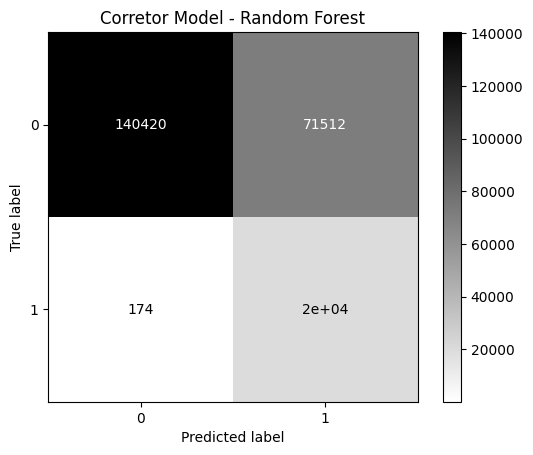

In [41]:
cm = confusion_matrix(teste2['y'], teste2['y_palavra'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary')
plt.title("Corretor Model - Random Forest")
plt.show()

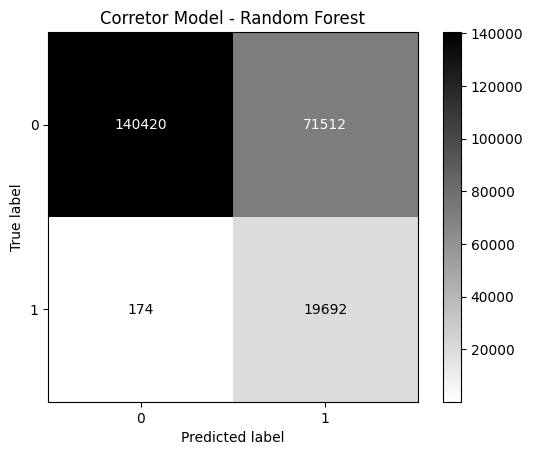

In [42]:
cm = confusion_matrix(teste2['y'], teste2['y_palavra'])

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

disp.plot(cmap='binary', values_format='d')

plt.title("Corretor Model - Random Forest")

plt.show() 

## CAPTURANDO OS NOVOS Falsos Positivos DO MODELO 2

In [43]:
fp_m1 = pd.read_csv(PATH_FALSOS_POSITIVOS_MODELO_1)
fp_m1

FileNotFoundError: [Errno 2] No such file or directory: '../../../BASES/experimento_corretor/resultados/modelo1_falsos_positivos.csv'

In [44]:
fp_m2 = teste2[(teste2['y'] == 0) & (teste2['y_palavra'] == 1)]
fp_m2 = fp_m2.drop(columns=['y', 'y_palavra'])
fp_m2

,palavra
1,NEFROLOGIA
4,ANOS
6,HORARIO
7,RENAL
8,PACIENTE
...,...
231791,CLINICA
231792,SAUDE
231793,BAIRRO
231796,RIO


In [45]:
fp_m2_novos = fp_m2[~fp_m2['palavra'].isin(fp_m1['palavra'])]
fp_m2_novos.to_csv(PATH_FALSOS_POSITIVOS_MODELO_2, index=False)

NameError: name 'fp_m1' is not defined

In [46]:
vector_input_temp_list

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,1,5,0,12
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,12
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,0
4,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,12,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
171401,0,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,13,12
171402,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
171403,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,13,12
171404,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,12


In [47]:
def bigrams_vector(lista_tokens):
    vectorizer = load('vectorizer.joblib')
    alfabeto = list(string.ascii_uppercase)
    alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]
    vector = vectorizer.transform(lista_tokens)
    return pd.DataFrame(vector.todense(), columns=alfabeto_bigrams)

print("Criando vetor de bigramas para os tokens...")
token = fp_m2_novos['palavra']
tokens_vector_bigrams = bigrams_vector(token.to_list())

Criando vetor de bigramas para os tokens...


NameError: name 'fp_m2_novos' is not defined

In [ ]:
alfabeto = list(string.ascii_uppercase)
alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]

In [ ]:
df_result = tokens_vector_bigrams.merge(vector_input_temp_list, on=alfabeto_bigrams, how='left')
df_result

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,6,12,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,2,12,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,6,12,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,2,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45350,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,12
45351,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,13
45352,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,13
45353,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,1


In [ ]:
df_result.drop_duplicates(subset=alfabeto_bigrams).shape

(581, 681)

Para verificar se se trata realmente dos 375 tokens ( falsos positivos novos )

In [ ]:
df_result.drop_duplicates(subset=alfabeto_bigrams).shape

(581, 681)

#### Estes tokens possuem vizinhos que são nomes?

Dos 375 tokens - 109 possuem ambos os vizinhos nomes ( tanto predecessor quando sucessor )

In [ ]:
pred_n_suce_n = df_result[(df_result['y_predecessor'] == 1) & (df_result['y_sucessor'] == 1)]
pred_n_suce_n.drop_duplicates(subset=alfabeto_bigrams)

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
30,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,7,12,12
153,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
228,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,1,12,13,12
278,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,13
366,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42936,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
43505,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,1,1,13,13,0
44038,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,13,12
44378,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12


Também entre estes tokens ( Os 375 ) 336 possuem ao menos um nome como vizinho

In [ ]:
pred_nw_suce_nw = df_result[(df_result['y_predecessor'] == 1) | (df_result['y_sucessor'] == 1)]
pred_nw_suce_nw.drop_duplicates(subset=alfabeto_bigrams)

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,12,12
17,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,0,12
20,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,6,12,0
24,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43505,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,1,1,13,13,0
44006,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,13,12
44371,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,13,12,12
44814,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12


Os numeros não batem, né? se somar. O motivo é simples, um mesmo token pode estar em uma posiçao.

y_p = 0 | y_s = 0  
y_p = 1 | y_s = 0  
  
y_p = 0 | y_s = 1  
y_p = 1 | y_s = 1  

In [ ]:
pred_w_suce_w = df_result[(df_result['y_predecessor'] == 0) & (df_result['y_sucessor'] == 0)]
pred_w_suce_w.drop_duplicates(subset=alfabeto_bigrams)

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,6,12,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
18,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,0,12
26,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,0
40,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42916,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
43058,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,13
43504,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,13
44007,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,13,1


Um mesmo tokem pode possuir classificaçoes de predecessores e sucessores diferentes nas bases?

In [ ]:
pred_nw_suce_nw = pred_nw_suce_nw.drop_duplicates(subset=alfabeto_bigrams)
pred_w_suce_w = pred_w_suce_w.drop_duplicates(subset=alfabeto_bigrams)

In [ ]:
intecessao = pred_w_suce_w.merge(pred_nw_suce_nw, on=alfabeto_bigrams, how='inner')
intecessao

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,y_predecessor_x,y_sucessor_x,cg_p_x,cg_w_x,cg_s_x,y_predecessor_y,y_sucessor_y,cg_p_y,cg_w_y,cg_s_y
0,0,0,0,0,0,0,0,0,0,0,...,0,0,6,12,0,0,1,13,12,12
1,0,0,0,0,0,0,0,0,0,0,...,0,0,12,12,12,0,1,1,12,12
2,0,0,0,0,0,0,0,0,0,0,...,0,0,12,0,12,0,1,12,0,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,13,12,0,0,1,12,12,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,13,12,0,1,0,12,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306,0,0,0,0,0,0,0,0,0,0,...,0,0,13,12,12,0,1,13,12,7
307,0,0,0,0,0,0,0,0,0,0,...,0,0,9,12,12,1,0,12,12,12
308,0,0,0,0,0,0,0,0,0,0,...,0,0,12,12,12,1,0,7,12,12
309,0,0,0,0,0,0,0,0,0,0,...,0,0,12,13,1,1,0,12,13,12


In [ ]:
v = pred_w_suce_w.merge(pred_nw_suce_nw, on=alfabeto_bigrams, how='inner')

if not v.empty:
    print("Existe interseção entre os DataFrames.")
else:
    print("Não existe interseção entre os DataFrames.")


Existe interseção entre os DataFrames.


#### Explicabilidade dos Falsos Positivos

In [ ]:
importancia_features = rf_corretor.feature_importances_

feature_names = df_result.columns 
importancia_df = pd.DataFrame({
    'Feature': feature_names,
    'Importância': importancia_features
}).sort_values(by='Importância', ascending=False)

importancia_df


,Feature,Importância
676,y_predecessor,0.067909
679,cg_w,0.059447
677,y_sucessor,0.041409
678,cg_p,0.040687
13,AN,0.033637
...,...,...
637,YN,0.000000
636,YM,0.000000
635,YL,0.000000
634,YK,0.000000


In [ ]:
import lime
import numpy as np
import lime.lime_tabular

predict_fn_rf = lambda x: rf_corretor.predict_proba(x).astype(float)

X = df_result.values

explainer = lime.lime_tabular.LimeTabularExplainer(X, feature_names=df_result.columns)

choosen_instance = df_result.values[13]

exp = explainer.explain_instance(choosen_instance, predict_fn_rf, num_features=10)

exp.show_in_notebook(show_all=False)


c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## Falsos negativos

In [48]:
fn = teste2[(teste2['y'] == 1) & (teste2['y_palavra'] == 0)]

In [49]:
fn

,palavra,y_palavra,y
3266,NEUROLOGISTA,0,1
11776,NEUROLOGISTA,0,1
12156,LOBO,0,1
13821,LOBO,0,1
21850,NEUROLOGISTA,0,1
...,...,...,...
228301,MACHADO,0,1
228446,ENFERMEIRO,0,1
228460,NEUROLOGISTA,0,1
228554,ENFERMEIRO,0,1


In [50]:
accuracy = accuracy_score(teste2['y'], teste2['y_palavra'])
accuracy

0.6907393506415068

In [51]:
precision = precision_score(teste2['y'], teste2['y_palavra'])
precision

np.float64(0.21591158282531467)

In [52]:
recall = recall_score(teste2['y'], teste2['y_palavra'])
recall

np.float64(0.9912413168227122)

In [53]:
f1 = f1_score(teste2['y'], teste2['y_palavra'])
f1

np.float64(0.3545871972629873)

In [54]:
import pandas as pd

# ==============================================================================
# ANÁLISE DE ERROS (Falsos Positivos e Falsos Negativos)
# ==============================================================================

print("--- INICIANDO ANÁLISE DE ERROS DO MODELO CORRETOR ---\n")

# 1. Identificar Falsos Positivos (FP)
# O modelo disse que é CLASSE 1 (Nome), mas o gabarito diz que é CLASSE 0 (Comum)
fp_df = teste2[(teste2['y_palavra'] == 1) & (teste2['y'] == 0)].copy()

# 2. Identificar Falsos Negativos (FN)
# O modelo disse que é CLASSE 0 (Comum), mas o gabarito diz que é CLASSE 1 (Nome)
fn_df = teste2[(teste2['y_palavra'] == 0) & (teste2['y'] == 1)].copy()

# ==============================================================================
# RELATÓRIO DE ERROS
# ==============================================================================

print(f"Total de Falsos Positivos (Alarme Falso): {len(fp_df)}")
print(f"Total de Falsos Negativos (Deixou Passar): {len(fn_df)}")
print("-" * 50)

# Selecionar colunas relevantes para visualização (ajuste conforme suas colunas reais)
# Geralmente queremos ver o contexto: Predecessor -> Palavra -> Sucessor
cols_to_show = ['predecessor', 'palavra', 'sucessor', 'y', 'y_palavra']

# Verifica se as colunas existem antes de tentar mostrar
cols_present = [c for c in cols_to_show if c in teste2.columns]

print("\n>>> TOP 10 FALSOS POSITIVOS (O modelo 'alucinou' nomes):")
if not fp_df.empty:
    display(fp_df[cols_present].head(10))
else:
    print("Nenhum Falso Positivo encontrado! (Excelente precisão)")

print("\n>>> TOP 10 FALSOS NEGATIVOS (O modelo perdeu nomes reais):")
if not fn_df.empty:
    display(fn_df[cols_present].head(10))
else:
    print("Nenhum Falso Negativo encontrado! (Excelente recall)")

# ==============================================================================
# EXPORTAÇÃO PARA ANÁLISE MANUAL
# ==============================================================================

# Cria uma pasta para salvar os relatórios de erro, se não existir
output_dir = 'relatorios_erro'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Salva em CSV
if not fp_df.empty:
    fp_df.to_csv(f'{output_dir}/falsos_positivos.csv', index=False, sep=';', encoding='utf-8-sig')
    print(f"\nArquivo salvo: {output_dir}/falsos_positivos.csv")

if not fn_df.empty:
    fn_df.to_csv(f'{output_dir}/falsos_negativos.csv', index=False, sep=';', encoding='utf-8-sig')
    print(f"Arquivo salvo: {output_dir}/falsos_negativos.csv")

--- INICIANDO ANÁLISE DE ERROS DO MODELO CORRETOR ---

Total de Falsos Positivos (Alarme Falso): 71512
Total de Falsos Negativos (Deixou Passar): 174
--------------------------------------------------

>>> TOP 10 FALSOS POSITIVOS (O modelo 'alucinou' nomes):


,palavra,y,y_palavra
1,NEFROLOGIA,0,1
4,ANOS,0,1
6,HORARIO,0,1
7,RENAL,0,1
8,PACIENTE,0,1
9,DIALISE,0,1
10,PERITONEAL,0,1
12,PERITONITE,0,1
14,CATETER,0,1
16,CREATININA,0,1



>>> TOP 10 FALSOS NEGATIVOS (O modelo perdeu nomes reais):


,palavra,y,y_palavra
3266,NEUROLOGISTA,1,0
11776,NEUROLOGISTA,1,0
12156,LOBO,1,0
13821,LOBO,1,0
21850,NEUROLOGISTA,1,0
22042,NEUROLOGISTA,1,0
22364,ENFERMEIRO,1,0
24775,NEUROLOGISTA,1,0
26772,NEUROLOGISTA,1,0
26911,MACHADO,1,0



Arquivo salvo: relatorios_erro/falsos_positivos.csv
Arquivo salvo: relatorios_erro/falsos_negativos.csv


In [55]:
def exibir_contagem_de_tokens(df_predicao, df_gabarito=None):
    """
    Realiza a contagem de tokens, palavras e nomes baseando-se na lista de saída 
    (output_list) e compara com o gabarito (teste2).
    """
    # Contagens da predição (df_predicao)
    total_tokens_brutos = len(df_predicao)
    
    # O token '#' é usado como delimitador de fim de relato (y_palavra == 2)
    total_delimitadores = len(df_predicao[df_predicao['y_palavra'] == 2])
    total_tokens_validos = total_tokens_brutos - total_delimitadores
    
    total_pred_palavras = len(df_predicao[df_predicao['y_palavra'] == 0])
    total_pred_nomes = len(df_predicao[df_predicao['y_palavra'] == 1])
    
    # Vocabulário único (ignorando o delimitador '#')
    tokens_unicos = df_predicao[df_predicao['y_palavra'] != 2]['palavra'].nunique()
    
    print("=== ESTATÍSTICAS GERAIS (output_list) ===")
    print(f"Total de relatos processados: {total_delimitadores}")
    print(f"Total de tokens brutos (incluindo separador '#'): {total_tokens_brutos}")
    print(f"Total de tokens úteis: {total_tokens_validos}")
    print(f"Total de tokens únicos (Vocabulário): {tokens_unicos}")
    
    print("\n=== CONTAGEM DA PREDIÇÃO (MODELOS) ===")
    print(f"-> Predição - Palavras comuns (y=0): {total_pred_palavras}")
    print(f"-> Predição - Nomes (y=1): {total_pred_nomes}")
    
    # Se o dataframe de gabarito ('teste2') for passado, faz a comparação
    if df_gabarito is not None and 'y' in df_gabarito.columns:
        total_gab_palavras = len(df_gabarito[df_gabarito['y'] == 0])
        total_gab_nomes = len(df_gabarito[df_gabarito['y'] == 1])
        
        print("\n=== CONTAGEM DO GABARITO (teste2) ===")
        print(f"-> Gabarito - Palavras comuns (y=0): {total_gab_palavras}")
        print(f"-> Gabarito - Nomes (y=1): {total_gab_nomes}")
        
        # Análise das diferenças
        diff_nomes = total_pred_nomes - total_gab_nomes
        print(f"\n[!] O modelo previu {abs(diff_nomes)} nomes a {'MAIS' if diff_nomes > 0 else 'MENOS'} que o gabarito real.")

# Executando a função com as variáveis já disponíveis na memória do seu notebook
exibir_contagem_de_tokens(output_list, teste2)

=== ESTATÍSTICAS GERAIS (output_list) ===
Total de relatos processados: 1885
Total de tokens brutos (incluindo separador '#'): 233683
Total de tokens úteis: 231798
Total de tokens únicos (Vocabulário): 11528

=== CONTAGEM DA PREDIÇÃO (MODELOS) ===
-> Predição - Palavras comuns (y=0): 140594
-> Predição - Nomes (y=1): 91204

=== CONTAGEM DO GABARITO (teste2) ===
-> Gabarito - Palavras comuns (y=0): 211932
-> Gabarito - Nomes (y=1): 19866

[!] O modelo previu 71338 nomes a MAIS que o gabarito real.
